## Task 1: Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import joblib

df = pd.read_csv("Customer_Subscription.csv")
df.head()

,Age,Monthly_Income,Internet_Usage,Previous_Contacts,Contact_Duration,Engagement_Score,Subscription
0,38,940000,50,3,9,6,0
1,35,850000,16,8,9,6,0
2,24,1980000,37,6,8,2,0
3,19,790000,93,4,18,5,1
4,59,820000,43,3,15,8,1


In [2]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDescriptive statistics:")
display(df.describe())
print("\nSubscription counts:")
print(df["Subscription"].value_counts())
print("\nSubscription percentages:")
print((df["Subscription"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (300, 7)

Data types:
Age                  int64
Monthly_Income       int64
Internet_Usage       int64
Previous_Contacts    int64
Contact_Duration     int64
Engagement_Score     int64
Subscription         int64
dtype: object

Missing values:
Age                  0
Monthly_Income       0
Internet_Usage       0
Previous_Contacts    0
Contact_Duration     0
Engagement_Score     0
Subscription         0
dtype: int64

Descriptive statistics:


,Age,Monthly_Income,Internet_Usage,Previous_Contacts,Contact_Duration,Engagement_Score,Subscription
count,300.000000,3.000000e+02,300.000000,300.000000,300.000000,300.000000,300.000000
mean,40.326667,1.040933e+06,42.986667,4.410000,10.883333,5.643333,0.310000
std,13.256157,6.399627e+05,23.180977,2.352377,5.502482,2.809942,0.463266
min,18.000000,2.500000e+05,6.000000,1.000000,1.000000,1.000000,0.000000
25%,29.000000,5.800000e+05,24.000000,2.000000,6.000000,3.000000,0.000000
50%,40.000000,9.000000e+05,39.500000,4.000000,11.000000,6.000000,0.000000
75%,50.250000,1.295000e+06,57.000000,6.250000,16.000000,8.000000,1.000000
max,65.000000,4.510000e+06,120.000000,8.000000,20.000000,10.000000,1.000000



Subscription counts:
Subscription
0    207
1     93
Name: count, dtype: int64

Subscription percentages:
Subscription
0    69.0
1    31.0
Name: proportion, dtype: float64


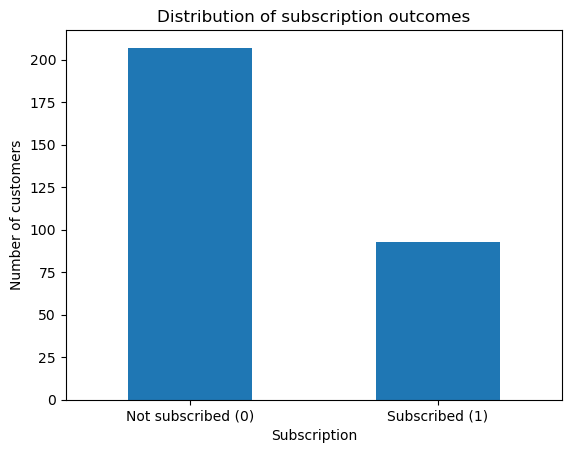

In [3]:
df["Subscription"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Not subscribed (0)", "Subscribed (1)"], rotation=0)
plt.ylabel("Number of customers")
plt.title("Distribution of subscription outcomes")
plt.show()

In [4]:
# Compare the average value of each predictor for the two subscription groups.
display(df.groupby("Subscription").mean(numeric_only=True).T)

Subscription,0,1
Age,3.980193e+01,4.149462e+01
Monthly_Income,1.042367e+06,1.037742e+06
Internet_Usage,4.058937e+01,4.832258e+01
Previous_Contacts,4.710145e+00,3.741935e+00
Contact_Duration,9.772947e+00,1.335484e+01
Engagement_Score,4.898551e+00,7.301075e+00


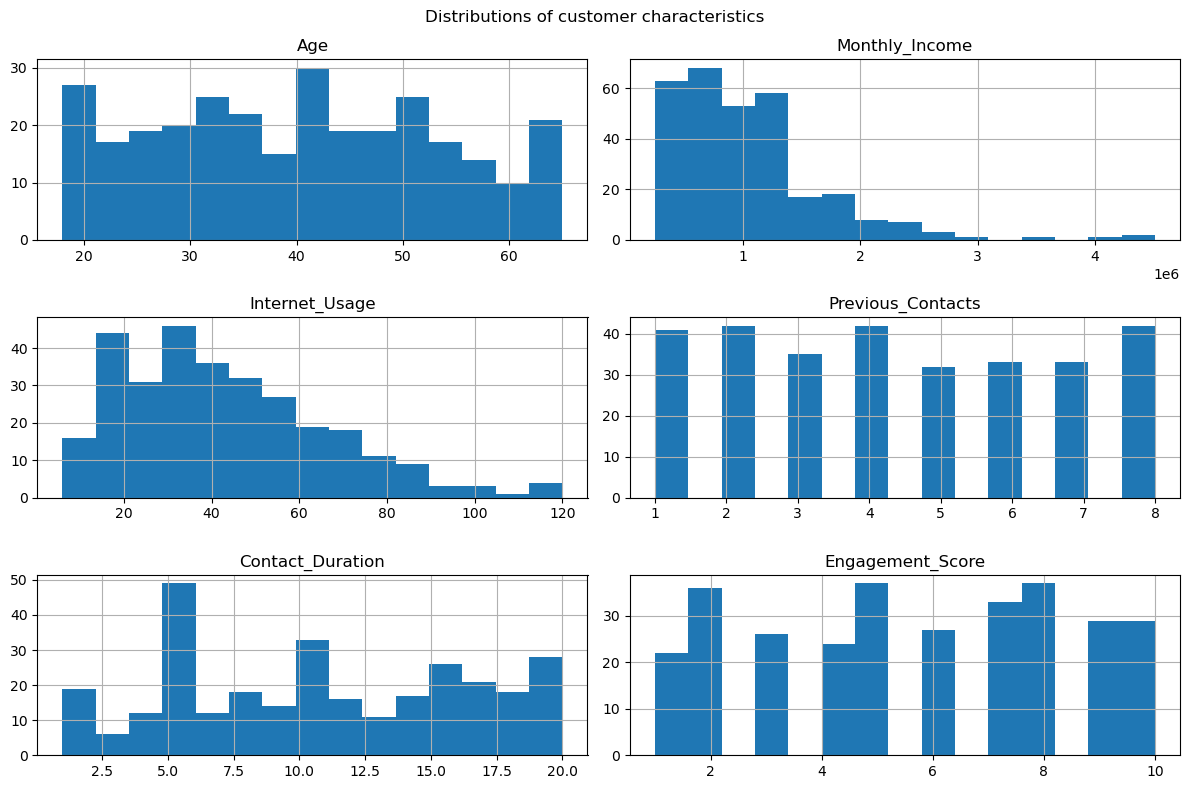

In [5]:
# Histograms for numerical predictors
df.drop(columns="Subscription").hist(figsize=(12, 8), bins=15)
plt.suptitle("Distributions of customer characteristics")
plt.tight_layout()
plt.show()

**Interpretation guide:** Subscription is the target. A value of 1 means subscribed and 0 means not subscribed. The dataset has 300 records and should be described using the actual outputs above. Do not interpret group averages as proof that a feature causes subscription.

## Task 2: Prepare the data and split it

In [6]:
X = df.drop(columns=["Subscription"])
y = df["Subscription"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(3))

X_train: (240, 6)
X_test: (60, 6)
y_train: (240,)
y_test: (60,)

Training target proportions:
Subscription
0    0.692
1    0.308
Name: proportion, dtype: float64

Testing target proportions:
Subscription
0    0.683
1    0.317
Name: proportion, dtype: float64


In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit only on training data
X_test_scaled = scaler.transform(X_test)        # apply same training scaler to test data

print("First 5 standardized training rows:")
display(pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index).head())

First 5 standardized training rows:


,Age,Monthly_Income,Internet_Usage,Previous_Contacts,Contact_Duration,Engagement_Score
116,0.234047,0.125857,0.143698,1.573705,0.213607,0.123620
38,1.288199,0.499770,-0.347704,0.709428,-0.500897,-1.306207
298,-1.648368,0.450999,0.635099,-1.019127,1.106737,-0.591293
115,-0.217733,-0.752026,0.322389,-1.019127,-1.572654,-1.306207
266,0.987013,-0.947111,1.081828,-0.154850,-0.500897,0.481077


**Why scale?** StandardScaler puts predictors on comparable scales. This helps optimization and makes coefficient magnitudes more comparable. The scaler is fitted only on training data to avoid allowing information from the test set to influence preprocessing.

**Why split?** The training set is used to learn model parameters. The test set provides an independent check on performance. `stratify=y` preserves approximately the same class proportions in both sets.

## Task 3 and 4: Train baseline, L1 and L2 models

In [8]:
models = {
    "Baseline": LogisticRegression(max_iter=1000, C=1.0),
    "L1": LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=1000),
    "L2": LogisticRegression(penalty="l2", solver="liblinear", C=1.0, max_iter=1000)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(name, "trained")

Baseline trained
L1 trained
L2 trained


In [9]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Baseline_Predicted": predictions["Baseline"],
    "L1_Predicted": predictions["L1"],
    "L2_Predicted": predictions["L2"]
}, index=y_test.index)
display(comparison.head(15))

,Actual,Baseline_Predicted,L1_Predicted,L2_Predicted
74,0,0,0,0
261,0,0,0,0
183,1,1,1,1
117,1,1,1,1
182,1,0,0,0
193,0,0,0,0
218,0,0,0,0
80,0,0,0,0
263,1,1,1,1
85,0,0,0,0


,Feature,Baseline,L1,L2
0,Age,0.0749,0.0492,0.0746
1,Monthly_Income,0.0650,0.0395,0.0641
2,Internet_Usage,0.2320,0.2064,0.2287
3,Previous_Contacts,-0.5004,-0.4779,-0.4950
4,Contact_Duration,0.7096,0.6970,0.7020
5,Engagement_Score,1.1989,1.1823,1.1833


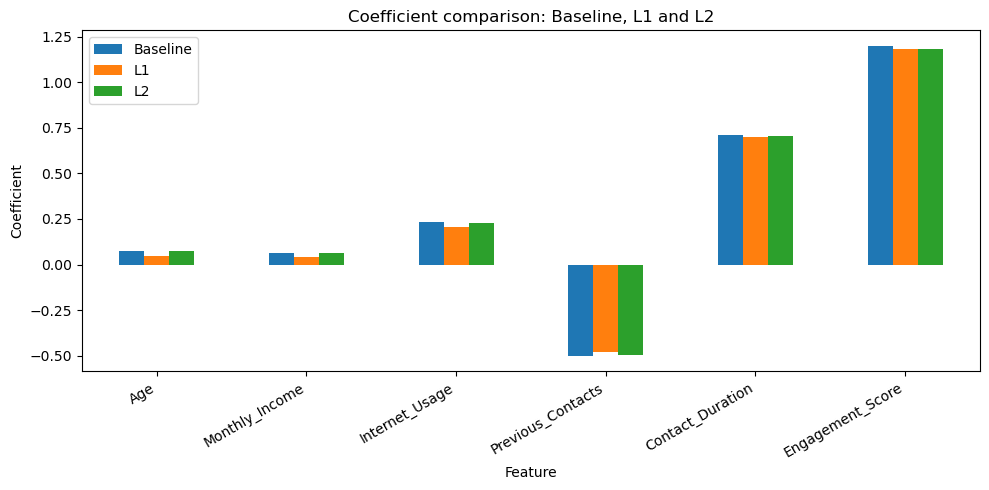

In [10]:
# Coefficients are for standardized predictors.
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Baseline": models["Baseline"].coef_[0],
    "L1": models["L1"].coef_[0],
    "L2": models["L2"].coef_[0]
})
display(coefficient_table.round(4))
coefficient_table.set_index("Feature").plot(kind="bar", figsize=(10, 5))
plt.title("Coefficient comparison: Baseline, L1 and L2")
plt.ylabel("Coefficient")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Regularization explanation:** L1 (Lasso) can shrink some coefficients exactly to zero, which can perform feature selection. L2 (Ridge) shrinks coefficients toward zero but generally retains them. A larger `C` means weaker regularization; a smaller `C` means stronger regularization. Coefficient signs indicate direction of association while holding the other model inputs constant.

## Task 5: Evaluate and compare all models

In [11]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })
results_df = pd.DataFrame(rows).sort_values("F1 Score", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.75,0.6429,0.4737,0.5455
1,L1,0.75,0.6429,0.4737,0.5455
2,L2,0.75,0.6429,0.4737,0.5455



 Baseline
Confusion matrix:
[[36  5]
 [10  9]]
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.64      0.47      0.55        19

    accuracy                           0.75        60
   macro avg       0.71      0.68      0.69        60
weighted avg       0.74      0.75      0.74        60



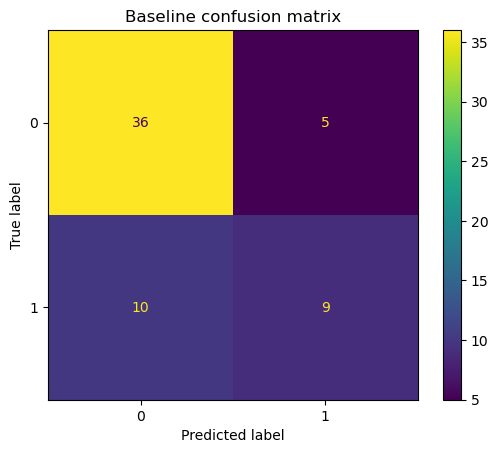


 L1
Confusion matrix:
[[36  5]
 [10  9]]
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.64      0.47      0.55        19

    accuracy                           0.75        60
   macro avg       0.71      0.68      0.69        60
weighted avg       0.74      0.75      0.74        60



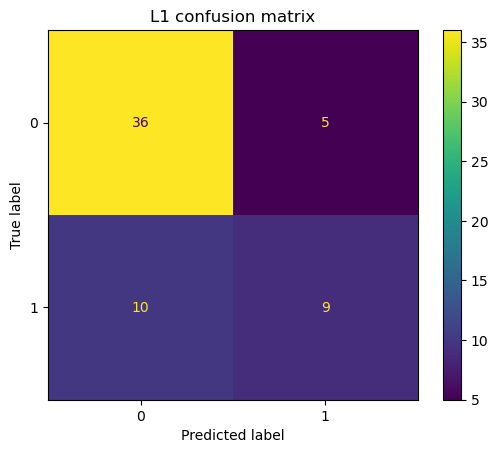


 L2
Confusion matrix:
[[36  5]
 [10  9]]
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.64      0.47      0.55        19

    accuracy                           0.75        60
   macro avg       0.71      0.68      0.69        60
weighted avg       0.74      0.75      0.74        60



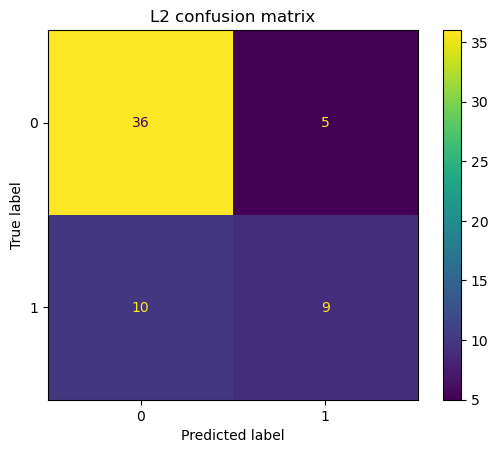

In [12]:
for name, pred in predictions.items():
    print("\n", name)
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name + " confusion matrix")
    plt.show()

**Model selection:** Use the test-set metrics and the project's intended use to justify a model. F1 balances precision and recall. In this run all three models produced the same metrics; L2 is selected as the deployment model as a regularized model, but it is not more accurate than the others on this split. Results may vary if the data or software version changes.

## Task 6: Save model and scaler; demonstrate the specified customer

In [13]:
# Save the L2 model and the fitted scaler.
selected_model = models["L2"]
joblib.dump(selected_model, "subscription_model.joblib")
joblib.dump(scaler, "subscription_scaler.joblib")
joblib.dump(list(X.columns), "feature_columns.joblib")
print("Saved model, scaler and feature order.")

Saved model, scaler and feature order.


In [14]:
sample_customer = pd.DataFrame([{
    "Age": 28,
    "Monthly_Income": 1200000,
    "Internet_Usage": 45,
    "Previous_Contacts": 3,
    "Contact_Duration": 8,
    "Engagement_Score": 7
}])[X.columns]

sample_scaled = scaler.transform(sample_customer)
predicted_class = selected_model.predict(sample_scaled)[0]
probability = selected_model.predict_proba(sample_scaled)[0, 1]

print("Predicted class:", predicted_class)
print("Probability of subscription:", round(probability * 100, 2), "%")
print("Interpretation:", "Likely to subscribe" if predicted_class == 1 else "Unlikely to subscribe")

Predicted class: 0
Probability of subscription: 34.3 %
Interpretation: Unlikely to subscribe


In [15]:
!pip install streamlit

In [ ]:
!streamlit run app.py

## Task 7: Conclusion and limitations

The notebook completes data inspection, preprocessing, logistic regression, L1/L2 comparison, evaluation and model export. The dataset contains only 300 observations, so results should be treated as an educational demonstration rather than a production guarantee. The model learns associations in the supplied data and does not establish causation. A real deployment should be tested on newer customer data, monitored for performance and fairness, and protect customer information.